In [58]:
# Importar paquetes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
)

from sklearn.model_selection import (
    GridSearchCV,
    cross_validate,
    train_test_split,
)
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.tree import DecisionTreeClassifier

from sklearn.tree import plot_tree



In [59]:
# Cargar los datos
df = pd.read_csv("ILPD.csv")

In [60]:
# Explorar los datos
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [61]:
# Retipado de valores
df_mod = df.copy()
df_mod['Gender'] = df_mod['Gender'].map({'Female': 0, 'Male': 1}) # se puede realizar en la pipeplane pero lo hicimos antes de verlo en clase
df_mod['Dataset'] = df_mod['Dataset'].map({1: 1, 2: 0})

In [62]:
# Mostrar las filas duplicadas
filas_duplicadas = df_mod[df_mod.duplicated(keep=False)]
print(f"Filas duplicadas a eliminar: {df_mod.duplicated().sum()}")
filas_duplicadas


Filas duplicadas a eliminar: 13


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
18,40,0,0.9,0.3,293,232,245,6.8,3.1,0.80,1
19,40,0,0.9,0.3,293,232,245,6.8,3.1,0.80,1
25,34,1,4.1,2.0,289,875,731,5.0,2.7,1.10,1
26,34,1,4.1,2.0,289,875,731,5.0,2.7,1.10,1
33,38,0,2.6,1.2,410,59,57,5.6,3.0,0.80,0
34,38,0,2.6,1.2,410,59,57,5.6,3.0,0.80,0
54,42,1,8.9,4.5,272,31,61,5.8,2.0,0.50,1
55,42,1,8.9,4.5,272,31,61,5.8,2.0,0.50,1
61,58,1,1.0,0.5,158,37,43,7.2,3.6,1.00,1
62,58,1,1.0,0.5,158,37,43,7.2,3.6,1.00,1


In [63]:
# Eliminar duplicados
df_mod = df_mod.drop_duplicates().reset_index(drop=True)
print(f"Número total de registros tras eliminar duplicados: {len(df_mod)}")

Número total de registros tras eliminar duplicados: 570


In [64]:
# Mostrar individuos con valores incorrectos

print(
    "Valores incorrectos:",
    (df_mod['Direct_Bilirubin'] > df_mod['Total_Bilirubin']).sum(),
    "\n"
)

condicion_incorrecta = df_mod['Direct_Bilirubin'] > df_mod['Total_Bilirubin']
incorrectos = df_mod[condicion_incorrecta]

print("Registros clínicamente incorrectos encontrados:")
print(incorrectos[['Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin','Dataset']])


Valores incorrectos: 3 

Registros clínicamente incorrectos encontrados:
     Age  Gender  Total_Bilirubin  Direct_Bilirubin  Dataset
233   55       1              1.8               9.0        1
248   33       1              1.5               7.0        1
266   48       0              1.0               1.4        1


In [65]:
# 1. Seleccionar columnas del índice 2 al 10 para evitar incluir las variables de edad, sexo y dataset
cols_rango = df_mod.columns[0:11]

# 2. Filtrar únicamente las variables numéricas de dicho rango (excluyendo 'Dataset')
cols_numericas = df_mod[cols_rango].select_dtypes(include=[np.number]).columns
if "Dataset" in cols_numericas:
    cols_numericas = cols_numericas.drop("Dataset")

# 3. Calcular cuartiles e IQR
Q1 = df_mod[cols_numericas].quantile(0.25)
Q3 = df_mod[cols_numericas].quantile(0.75)
IQR = Q3 - Q1

# Límites para detectar valores atípicos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 4. Crear la máscara booleana directamente en una variable (sin agregar columna al DataFrame)
mask_atipicos = (
    (df_mod[cols_numericas] < limite_inferior)
    | (df_mod[cols_numericas] > limite_superior)
).any(axis=1)

# 5. Filtrar el DataFrame utilizando la máscara
individuos_atipicos = df_mod[mask_atipicos]
atipicos_dataset_1 = individuos_atipicos[individuos_atipicos["Dataset"] == 1] #Queremos saber cuantos de esos individuos con valores atípicos estan enfermos

print(
    f"Total de individuos señalados con valores atípicos: {len(individuos_atipicos)}"
)
print(
    f"De los cuales pertenecen a Dataset = 1: {len(atipicos_dataset_1)} pacientes"
)

# Mostrar la vista previa limpia con las columnas originales
individuos_atipicos.head()

Total de individuos señalados con valores atípicos: 291
De los cuales pertenecen a Dataset = 1: 231 pacientes


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
6,26,0,0.9,0.2,154,16,12,7.0,3.5,1.00,1
7,29,0,0.9,0.3,202,14,11,6.7,3.6,1.10,1


In [66]:
# Muestra solo las filas donde 'Albumin_and_Globulin_Ratio' es nulo
indices_nulos = df_mod[df_mod['Albumin_and_Globulin_Ratio'].isna()].index
df_mod[df_mod['Albumin_and_Globulin_Ratio'].isna()]

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
196,45,0,0.9,0.3,189,23,33,6.6,3.9,NaN,1
228,51,1,0.8,0.2,230,24,46,6.5,3.1,NaN,1
240,35,0,0.6,0.2,180,12,15,5.2,2.7,NaN,0
299,27,1,1.3,0.6,106,25,54,8.5,4.8,NaN,0


In [67]:
# Clases desbalanceadas en la data.frame original
counts = df['Dataset'].value_counts()
props = df['Dataset'].value_counts(normalize=True) * 100
for val in counts.index:
    print(f"Clase {val}: {counts[val]} pacientes ({props[val]:.2f}%)")

Clase 1: 416 pacientes (71.36%)
Clase 2: 167 pacientes (28.64%)


In [68]:
# Clases desbalanceadas post tratamiento
counts = df_mod['Dataset'].value_counts()
props = df_mod['Dataset'].value_counts(normalize=True) * 100
for val in counts.index:
    print(f"Clase {val}: {counts[val]} pacientes ({props[val]:.2f}%)")

Clase 1: 406 pacientes (71.23%)
Clase 0: 164 pacientes (28.77%)


In [69]:
df_mod.info()
df_mod.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 570 entries, 0 to 569
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         570 non-null    int64  
 1   Gender                      570 non-null    int64  
 2   Total_Bilirubin             570 non-null    float64
 3   Direct_Bilirubin            570 non-null    float64
 4   Alkaline_Phosphotase        570 non-null    int64  
 5   Alamine_Aminotransferase    570 non-null    int64  
 6   Aspartate_Aminotransferase  570 non-null    int64  
 7   Total_Protiens              570 non-null    float64
 8   Albumin                     570 non-null    float64
 9   Albumin_and_Globulin_Ratio  566 non-null    float64
 10  Dataset                     570 non-null    int64  
dtypes: float64(5), int64(6)
memory usage: 49.1 KB


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
count,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,566.000000,570.000000
mean,44.849123,0.754386,3.321754,1.497544,291.750877,79.728070,109.380702,6.496316,3.148947,0.948004,0.712281
std,16.242182,0.430829,6.267941,2.833231,245.291859,181.471697,290.880671,1.088300,0.796813,0.319635,0.453097
min,4.000000,0.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,0.000000
25%,33.000000,1.000000,0.800000,0.200000,176.000000,23.000000,25.000000,5.800000,2.600000,0.700000,0.000000
50%,45.000000,1.000000,1.000000,0.300000,208.000000,35.000000,41.000000,6.600000,3.100000,0.950000,1.000000
75%,58.000000,1.000000,2.600000,1.300000,298.000000,60.000000,86.750000,7.200000,3.800000,1.100000,1.000000
max,90.000000,1.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,1.000000


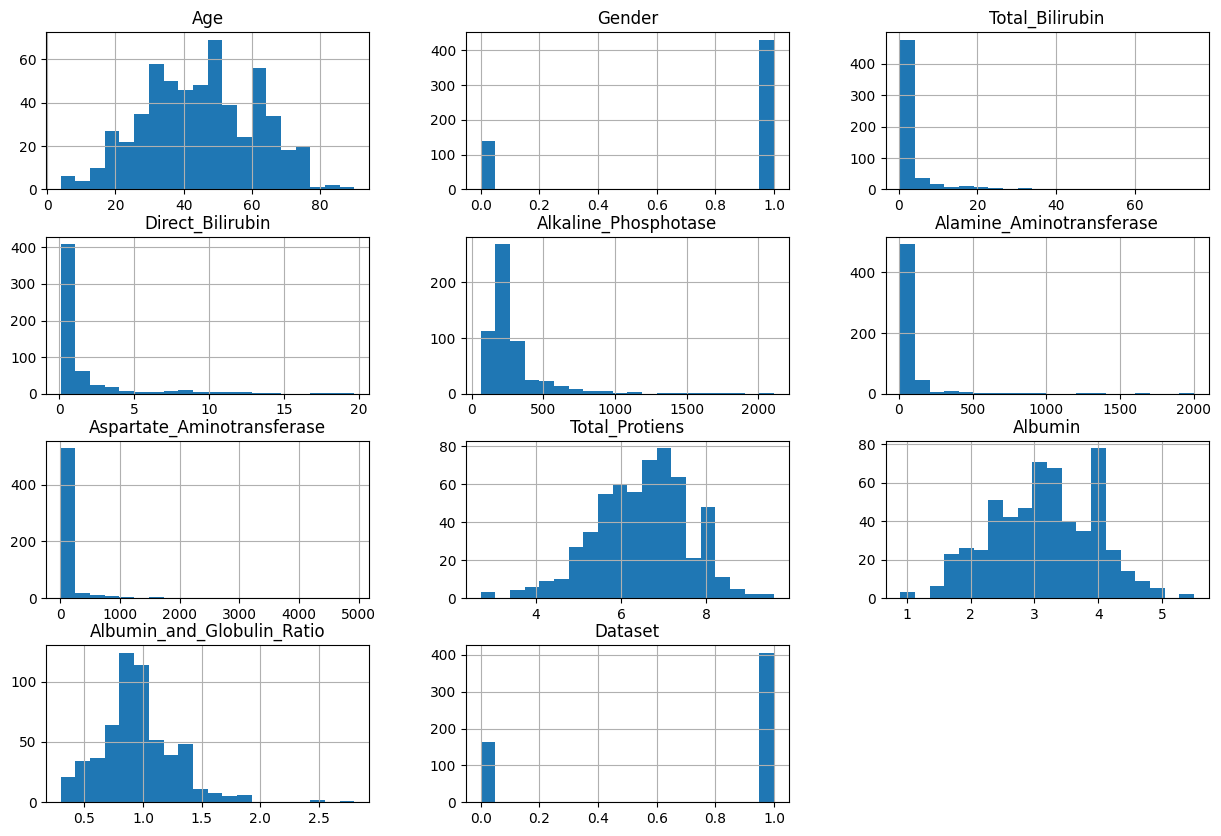

In [70]:
df_mod.hist(bins=20, figsize=(15,10))
plt.show()

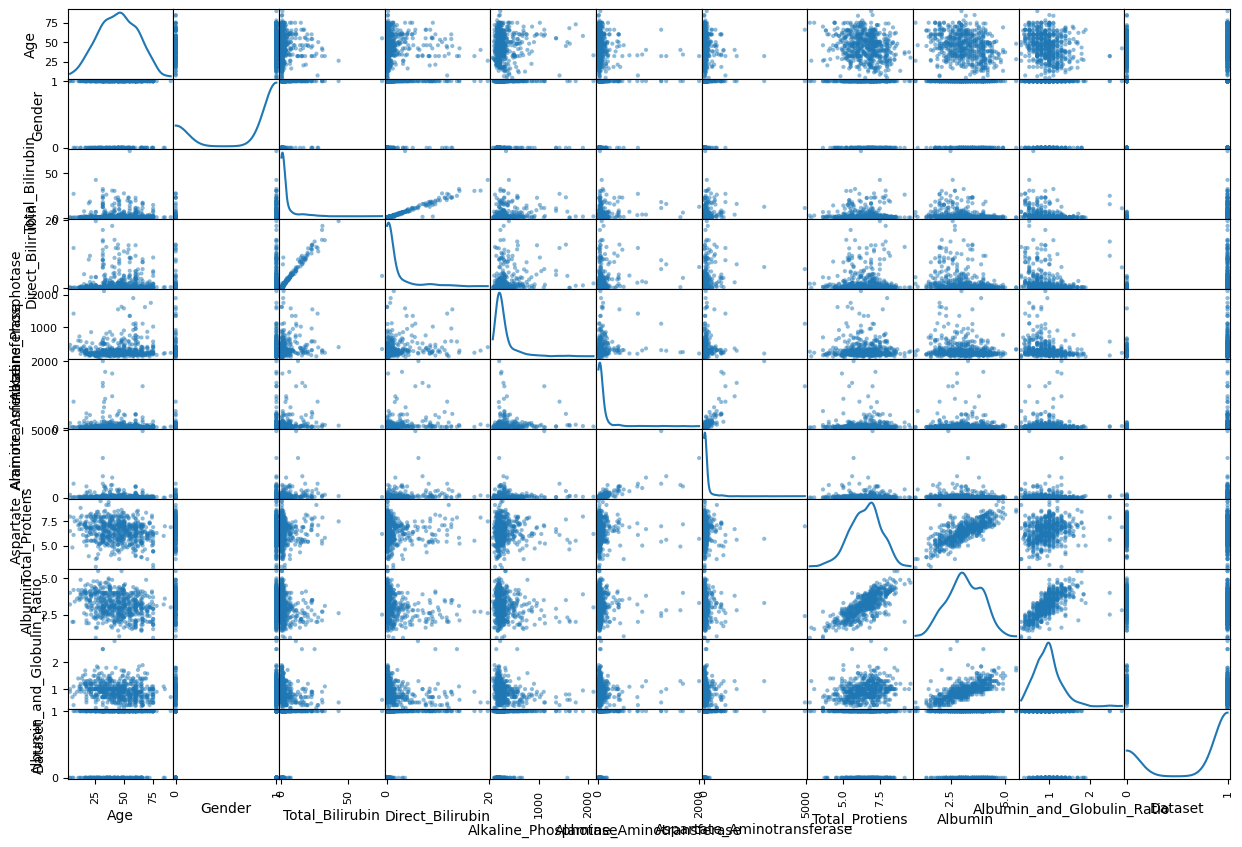

In [71]:
cd xpd.plotting.scatter_matrix(df_mod, figsize=(15,10), diagonal='kde')
plt.show()

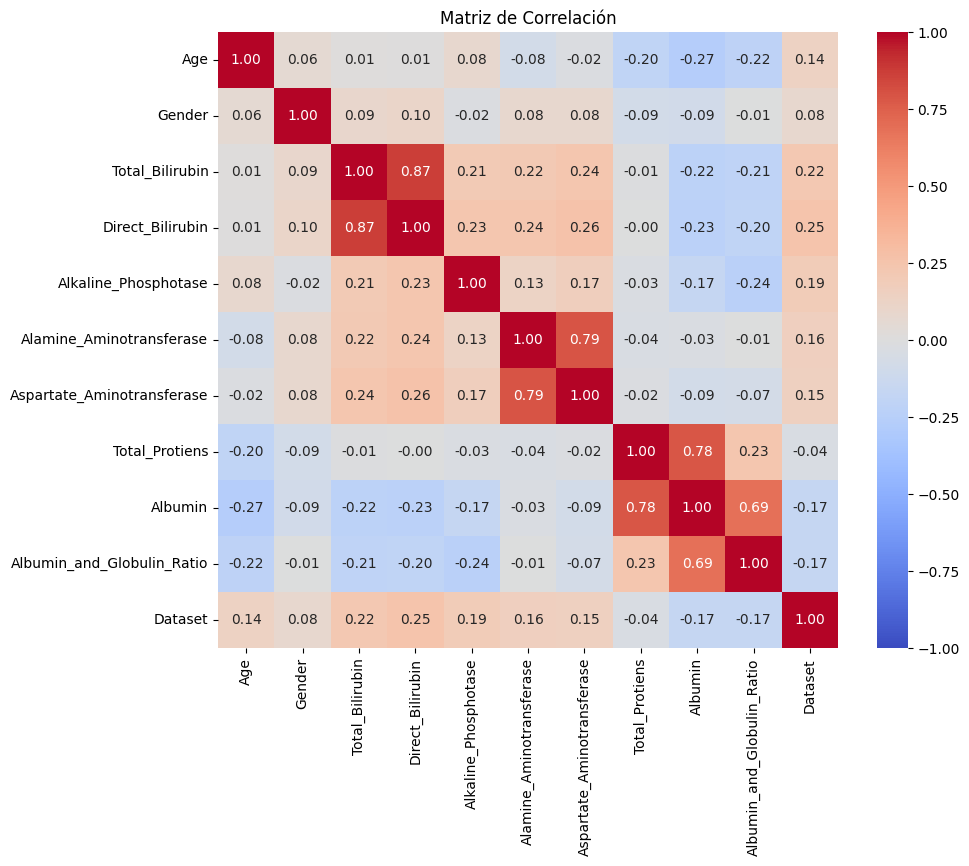

In [72]:
# Matriz de correlaciones
corr = df_mod.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matriz de Correlación")
plt.show()

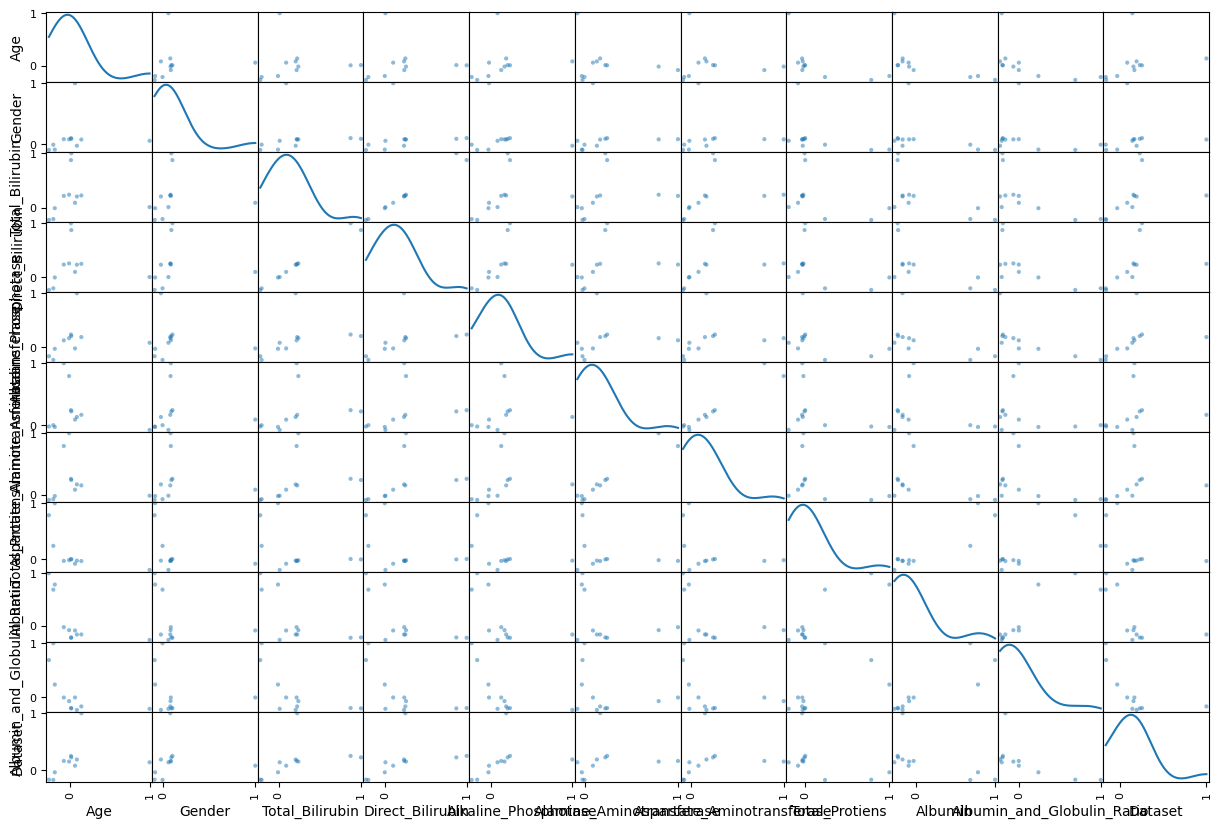

In [73]:
pd.plotting.scatter_matrix(corr, figsize=(15,10), diagonal='kde')
plt.show()

In [74]:
#Separo variables predictoras y variable respuesta
X = df_mod.drop(columns=['Dataset'])
y = df_mod['Dataset']

# Realizamos la división ANTES de calcular medianas o imputar nulos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [75]:
# El Pipeline calcula la mediana SOLO en X_train y se la aplica a X_train y a X_test
pipeline_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # Imputación por mediana basada en train
    ('tree', DecisionTreeClassifier(random_state=42)) # El árbol no requiere estandarización
])

# Rango de hiperparámetros
param_grid_tree = {
    'tree__max_depth': [3, 4, 5, 7, 10], # asignamos rango de valores a los hiperparámetros
    'tree__min_samples_split': [2, 4, 5, 10],
    'tree__min_samples_leaf': [1, 2, 4]
}

# Métricas a calcular
scoring_tree = {
    'accuracy': 'accuracy', #indicamos las métricas que nos interesa conocer
    'balanced_accuracy': 'balanced_accuracy',
    'f1': 'f1'
}

grid_tree = GridSearchCV(
    estimator=pipeline_tree,
    param_grid=param_grid_tree,
    cv=10, # el numero de folds
    scoring=scoring_tree,
    refit='accuracy',  # Criterio principal fijado en Accuracy por normativa
    return_train_score=True,  # Necesario para evaluar overfitting
    n_jobs=-1
)



In [76]:
grid_tree.fit(X_train, y_train)

# Extracción de métricas para el mejor modelo (seleccionado por Accuracy)
best_idx = grid_tree.best_index_
print(f"Mejores hiperparámetros Árbol: {grid_tree.best_params_}")
print(f"CV Accuracy:          {grid_tree.cv_results_['mean_test_accuracy'][best_idx]:.4f}")
print(f"CV Balanced Accuracy: {grid_tree.cv_results_['mean_test_balanced_accuracy'][best_idx]:.4f}")
print(f"CV F1-Score:          {grid_tree.cv_results_['mean_test_f1'][best_idx]:.4f}\n")



Mejores hiperparámetros Árbol: {'tree__max_depth': 3, 'tree__min_samples_leaf': 1, 'tree__min_samples_split': 10}
CV Accuracy:          0.6514
CV Balanced Accuracy: 0.4964
CV F1-Score:          0.7757



In [77]:
# Comprobar la mejor configuración según el estimador
print("Mejor combinación de GridSearchCV (refit='accuracy'):")
print(grid_tree.best_params_)
print(f"Accuracy del mejor modelo: {grid_tree.best_score_:.4f}")

# Ver las mejores filas de resultados según test accuracy medio
resultados_df = pd.DataFrame(grid_tree.cv_results_)
columnas = [
    'param_tree__max_depth',
    'param_tree__min_samples_split',
    'param_tree__min_samples_leaf',
    'mean_test_accuracy',
    'mean_test_balanced_accuracy',
    'mean_test_f1'
]

print("\nConfiguraciones ordenadas por 'mean_test_accuracy' descendente:")
display(resultados_df[columnas].sort_values(by='mean_test_accuracy', ascending=False).head(10))

Mejor combinación de GridSearchCV (refit='accuracy'):
{'tree__max_depth': 3, 'tree__min_samples_leaf': 1, 'tree__min_samples_split': 10}
Accuracy del mejor modelo: 0.6514

Configuraciones ordenadas por 'mean_test_accuracy' descendente:


,param_tree__max_depth,param_tree__min_samples_split,param_tree__min_samples_leaf,mean_test_accuracy,mean_test_balanced_accuracy,mean_test_f1
3,3,10,1,0.651449,0.496351,0.775734
7,3,10,2,0.651449,0.496351,0.775734
31,5,10,2,0.651401,0.520931,0.770266
27,5,10,1,0.651401,0.520931,0.770037
2,3,5,1,0.649275,0.494788,0.774162
4,3,2,2,0.649275,0.494788,0.774162
5,3,4,2,0.649275,0.494788,0.774162
6,3,5,2,0.649275,0.494788,0.774162
0,3,2,1,0.649275,0.494788,0.774162
1,3,4,1,0.649275,0.494788,0.774162


In [78]:

# 1. Convertir los resultados a DataFrame
resultados_grid = pd.DataFrame(grid_tree.cv_results_)

# 2. Seleccionar las columnas relevantes (parámetros y métricas medias)
columnas_interes = [
    'param_tree__max_depth',
    'param_tree__min_samples_split',
    'param_tree__min_samples_leaf',
    'mean_test_balanced_accuracy',
    'mean_test_accuracy',
    'mean_test_f1'
]

# 3. Filtrar y ordenar por Balanced Accuracy descendente
tabla_top10 = resultados_grid[columnas_interes].sort_values(
    by='mean_test_accuracy', ascending=False
).head(10)

# Mostrar la tabla (si usas Jupyter/Colab, display formatea la tabla visualmente)
print("TOP 10 CONFIGURACIONES")
display(tabla_top10)

TOP 10 CONFIGURACIONES


,param_tree__max_depth,param_tree__min_samples_split,param_tree__min_samples_leaf,mean_test_balanced_accuracy,mean_test_accuracy,mean_test_f1
3,3,10,1,0.496351,0.651449,0.775734
7,3,10,2,0.496351,0.651449,0.775734
31,5,10,2,0.520931,0.651401,0.770266
27,5,10,1,0.520931,0.651401,0.770037
2,3,5,1,0.494788,0.649275,0.774162
4,3,2,2,0.494788,0.649275,0.774162
5,3,4,2,0.494788,0.649275,0.774162
6,3,5,2,0.494788,0.649275,0.774162
0,3,2,1,0.494788,0.649275,0.774162
1,3,4,1,0.494788,0.649275,0.774162


In [79]:
# Convertir los resultados de GridSearchCV a un DataFrame de pandas
results_tree_df = pd.DataFrame(grid_tree.cv_results_)

# Convertir hiperparámetros a formato legible para las gráficas
results_tree_df['max_depth'] = results_tree_df['param_tree__max_depth'].astype(str)
results_tree_df['min_samples_split'] = results_tree_df['param_tree__min_samples_split'].astype(str)
results_tree_df['min_samples_leaf'] = results_tree_df['param_tree__min_samples_leaf'].astype(str)

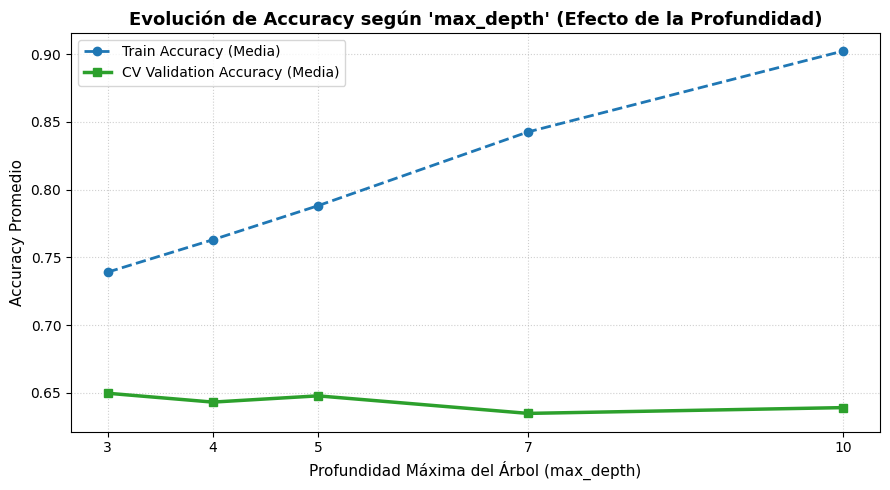

In [80]:
# Promediar el rendimiento según max_depth
depth_summary = results_tree_df.groupby('param_tree__max_depth').agg({
    'mean_train_accuracy': 'mean',
    'mean_test_accuracy': 'mean'
}).reset_index() #agrupamos por max_depth y miramos el accurasy medio que nos salen

plt.figure(figsize=(9, 5))
plt.plot(depth_summary['param_tree__max_depth'], depth_summary['mean_train_accuracy'],
         marker='o', label='Train Accuracy (Media)', color='#1f77b4', linestyle='--', linewidth=2)
plt.plot(depth_summary['param_tree__max_depth'], depth_summary['mean_test_accuracy'],
         marker='s', label='CV Validation Accuracy (Media)', color='#2ca02c', linewidth=2.5)

plt.title("Evolución de Accuracy según 'max_depth' (Efecto de la Profundidad)", fontsize=13, fontweight='bold')
plt.xlabel("Profundidad Máxima del Árbol (max_depth)", fontsize=11)
plt.ylabel("Accuracy Promedio", fontsize=11)
plt.xticks(depth_summary['param_tree__max_depth'])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

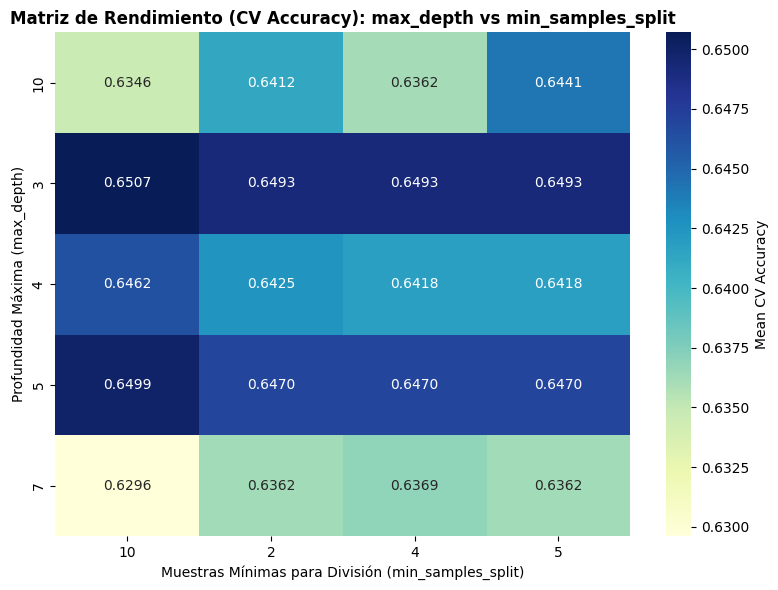

In [81]:
# Crear tabla pivote con la media del CV Accuracy
pivot_tree = results_tree_df.pivot_table(
    index='max_depth',
    columns='min_samples_split',
    values='mean_test_accuracy',
    aggfunc='mean'
)

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_tree, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'Mean CV Accuracy'})
plt.title("Matriz de Rendimiento (CV Accuracy): max_depth vs min_samples_split", fontsize=12, fontweight='bold')
plt.xlabel("Muestras Mínimas para División (min_samples_split)", fontsize=10)
plt.ylabel("Profundidad Máxima (max_depth)", fontsize=10)
plt.tight_layout()
plt.show()

In [82]:
# Evaluaciones Train vs Test para detección de Overfitting
y_pred_tree_train = grid_tree.predict(X_train)
y_pred_tree_test = grid_tree.predict(X_test) #EVALUAMOS EL MODELO

print("--- EVALUACIÓN ÁRBOL (TRAIN vs TEST) ---")
print(f"Train Accuracy:          {accuracy_score(y_train, y_pred_tree_train):.4f} | Test Accuracy:          {accuracy_score(y_test, y_pred_tree_test):.4f}")
print(f"Train Balanced Accuracy: {balanced_accuracy_score(y_train, y_pred_tree_train):.4f} | Test Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_tree_test):.4f}")
print(f"Train F1-Score:          {f1_score(y_train, y_pred_tree_train):.4f} | Test F1-Score:          {f1_score(y_test, y_pred_tree_test):.4f}\n")



--- EVALUACIÓN ÁRBOL (TRAIN vs TEST) ---
Train Accuracy:          0.7325 | Test Accuracy:          0.7368
Train Balanced Accuracy: 0.6619 | Test Balanced Accuracy: 0.6442
Train F1-Score:          0.8152 | Test F1-Score:          0.8235



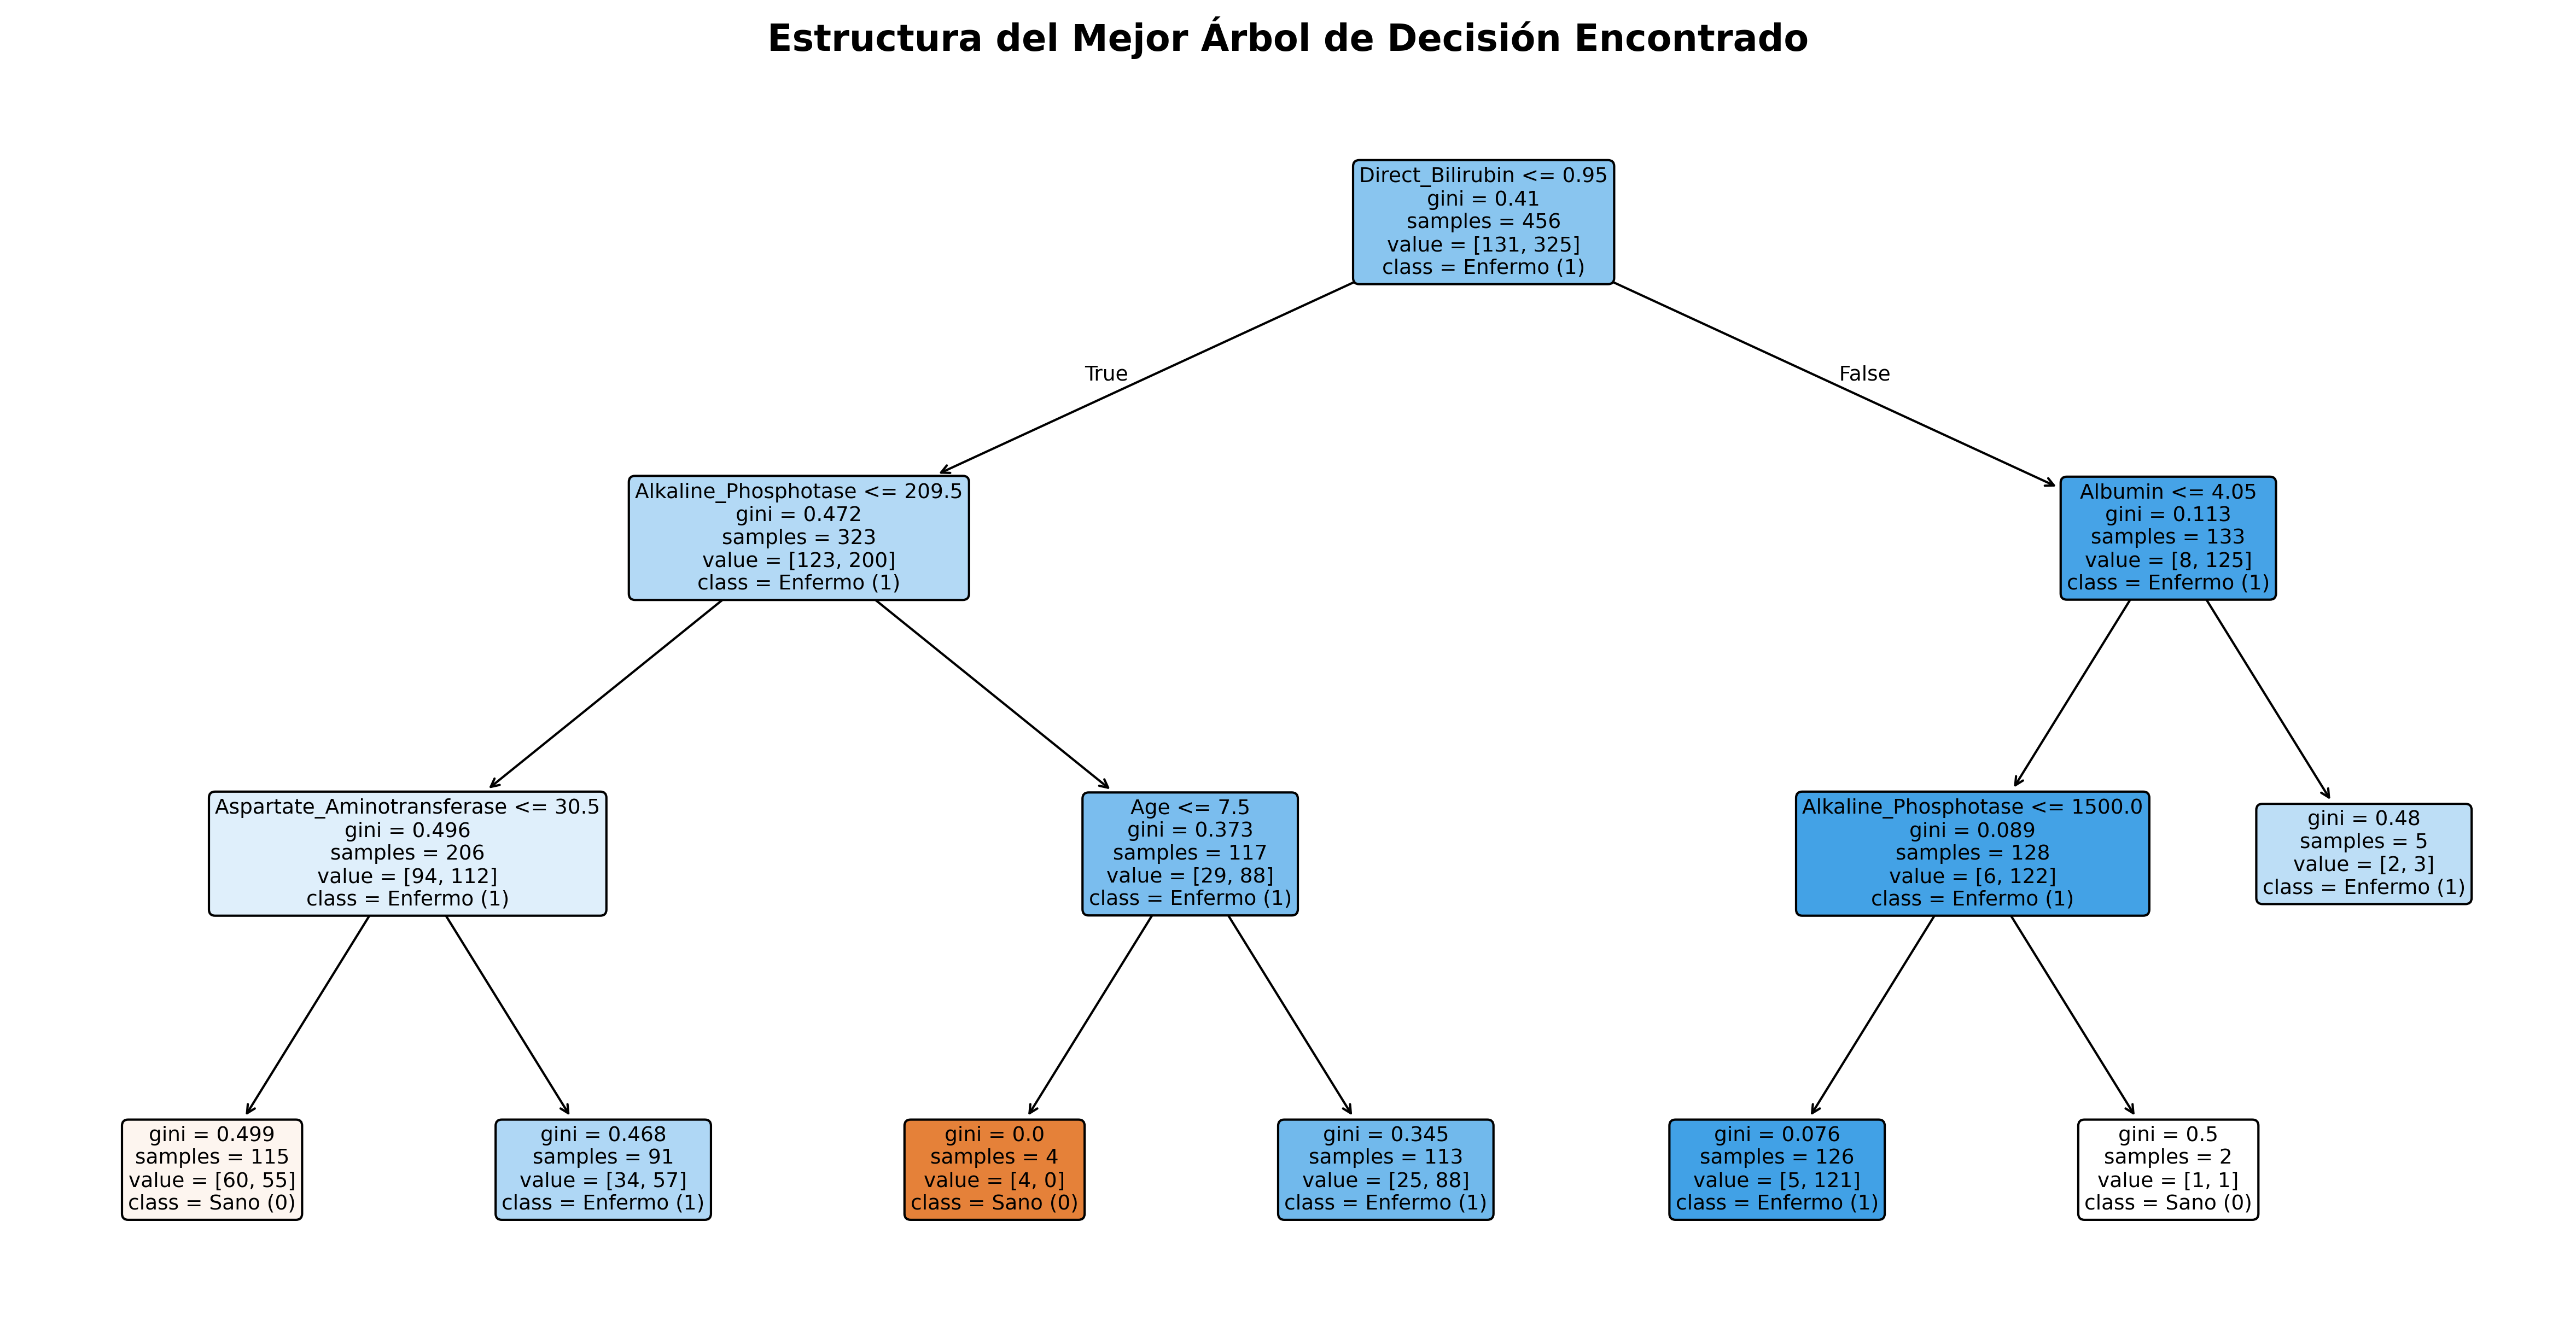

In [83]:

# 1. Extraer el mejor Pipeline y el paso correspondiente al Árbol
best_pipeline = grid_tree.best_estimator_
best_tree = best_pipeline.named_steps['tree']

# 2. Obtener los nombres de las columnas (variables predictoras)
feature_names = X.columns.tolist()

# 3. Dibujar el árbol de decisión
plt.figure(figsize=(20, 10), dpi=300) # Tamaño amplio para visualizar bien las divisiones

plot_tree(
    best_tree,
    feature_names=feature_names,
    class_names=['Sano (0)', 'Enfermo (1)'],
    filled=True,          # Colorea los nodos según la clase predicha y su pureza
    rounded=True,         # Bordes redondeados
    fontsize=9            # Tamaño de la letra
)

plt.title("Estructura del Mejor Árbol de Decisión Encontrado", fontsize=16, fontweight='bold')
plt.show()

In [84]:
# Modelo final

# 1. Extraer los mejores hiperparámetros seleccionados por GridSearchCV
best_params_tree = grid_tree.best_params_

# 2. Construir el Pipeline final para el Árbol de Decisión
final_pipeline_tree = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeClassifier(
        max_depth=best_params_tree['tree__max_depth'],
        min_samples_split=best_params_tree['tree__min_samples_split'],
        min_samples_leaf=best_params_tree['tree__min_samples_leaf'],
        random_state=42
    ))
])

# 3. Entrenar el modelo con el 100% del dataset
final_pipeline_tree.fit(X, y)

print("--- MODELO FINAL: ÁRBOL DE DECISIÓN ---")
print("¡Entrenamiento completado sobre la totalidad de los datos!")
print(f"Configuración aplicada: {best_params_tree}")

--- MODELO FINAL: ÁRBOL DE DECISIÓN ---
¡Entrenamiento completado sobre la totalidad de los datos!
Configuración aplicada: {'tree__max_depth': 3, 'tree__min_samples_leaf': 1, 'tree__min_samples_split': 10}


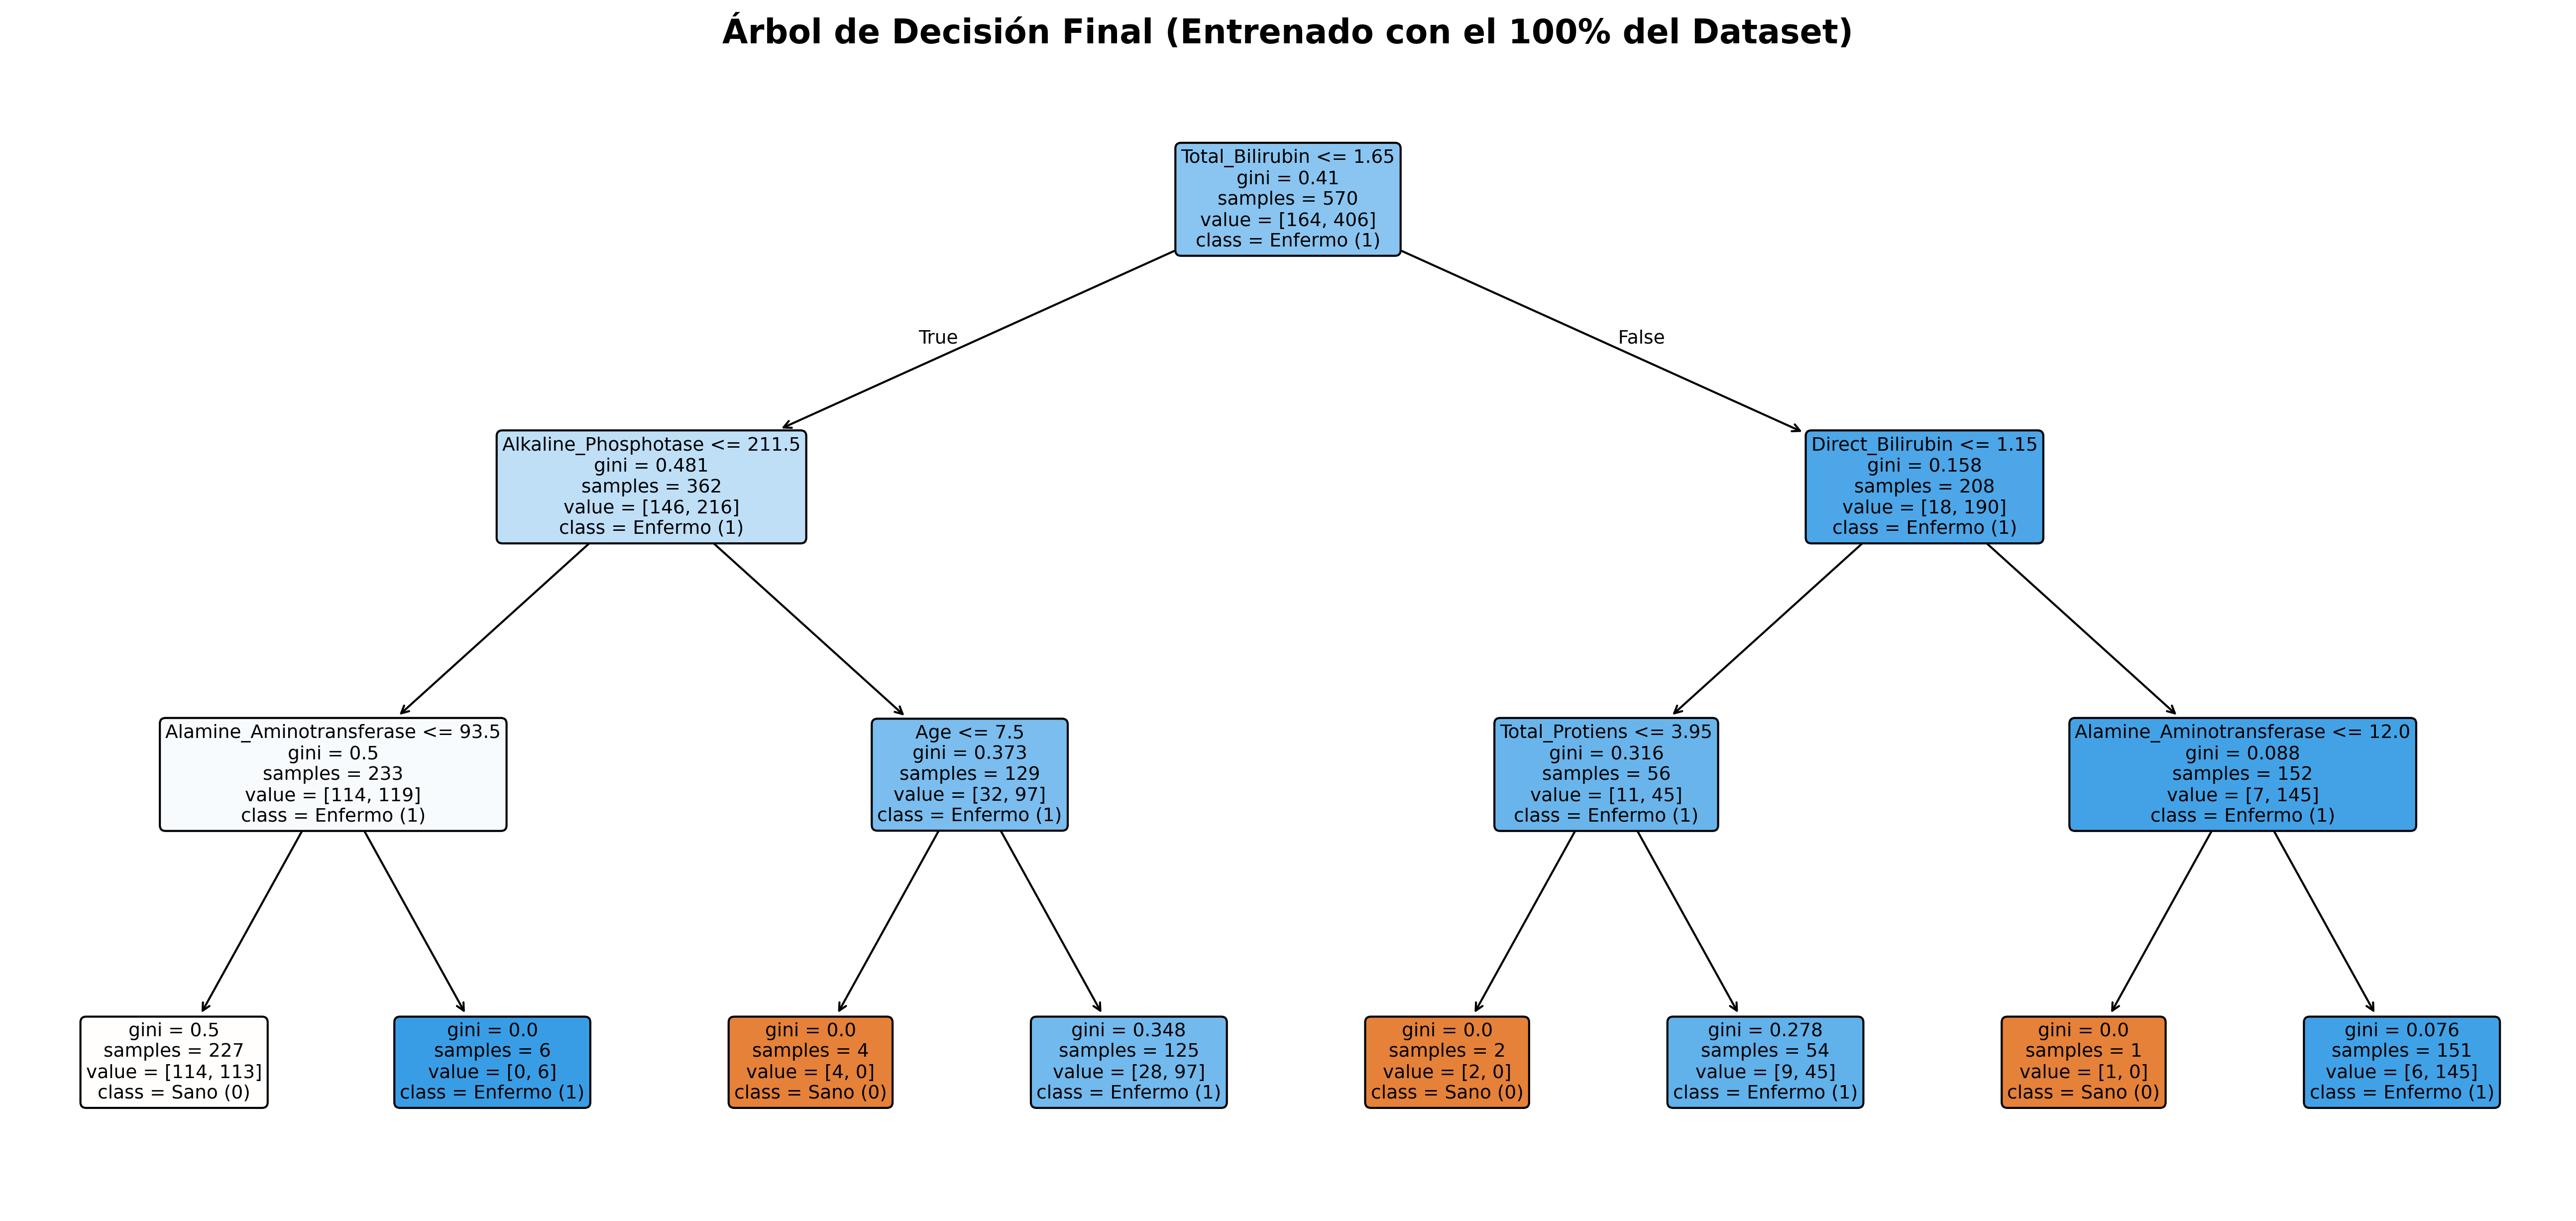

In [85]:
# Visualización del Árbol de Decisión Final
plt.figure(figsize=(22, 10), dpi=300)

plot_tree(
    final_pipeline_tree.named_steps['tree'],
    feature_names=X.columns.tolist(),
    class_names=['Sano (0)', 'Enfermo (1)'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Árbol de Decisión Final (Entrenado con el 100% del Dataset)", fontsize=16, fontweight='bold')
plt.show()

In [86]:
pipeline_knn = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',RobustScaler()), # aplicamos escalado robusto para reducir el impacto de los atípicos
    ('knn', KNeighborsClassifier())
])

# Rango de vecinos y tipos de ponderación
num_vecinos = list(range(1, 21,2))
pesos = ['distance', 'uniform']
metricas = ['accuracy', 'balanced_accuracy', 'f1']

registros_knn = []

for weight in pesos:
    for k in num_vecinos:
        pipeline_knn.set_params(knn__n_neighbors=k, knn__weights=weight)

        res_cv = cross_validate(
            pipeline_knn,
            X_train,
            y_train,
            cv=10,
            scoring=metricas,
            return_train_score=True,
            n_jobs=-1
        )

        registros_knn.append({
            'k': k,
            'weights': weight,
            'train_accuracy': res_cv['train_accuracy'].mean(),
            'val_accuracy': res_cv['test_accuracy'].mean(),
            'train_f1': res_cv['train_f1'].mean(),
            'val_f1': res_cv['test_f1'].mean(),
            'val_balanced_accuracy': res_cv['test_balanced_accuracy'].mean()
        })

df_results_knn = pd.DataFrame(registros_knn)

# Selección de la mejor configuración basada en Accuracy
mejor_config = df_results_knn.sort_values(by='val_accuracy', ascending=False).iloc[0]

print(f"MEJOR CONFIGURACIÓN KNN (por Accuracy): K={int(mejor_config['k'])}, weights='{mejor_config['weights']}'")
print(f"CV Accuracy medio:          {mejor_config['val_accuracy']:.4f}")
print(f"CV Balanced Accuracy medio: {mejor_config['val_balanced_accuracy']:.4f}")
print(f"CV F1-Score medio:          {mejor_config['val_f1']:.4f}\n")

MEJOR CONFIGURACIÓN KNN (por Accuracy): K=17, weights='distance'
CV Accuracy medio:          0.7125
CV Balanced Accuracy medio: 0.5793
CV F1-Score medio:          0.8153



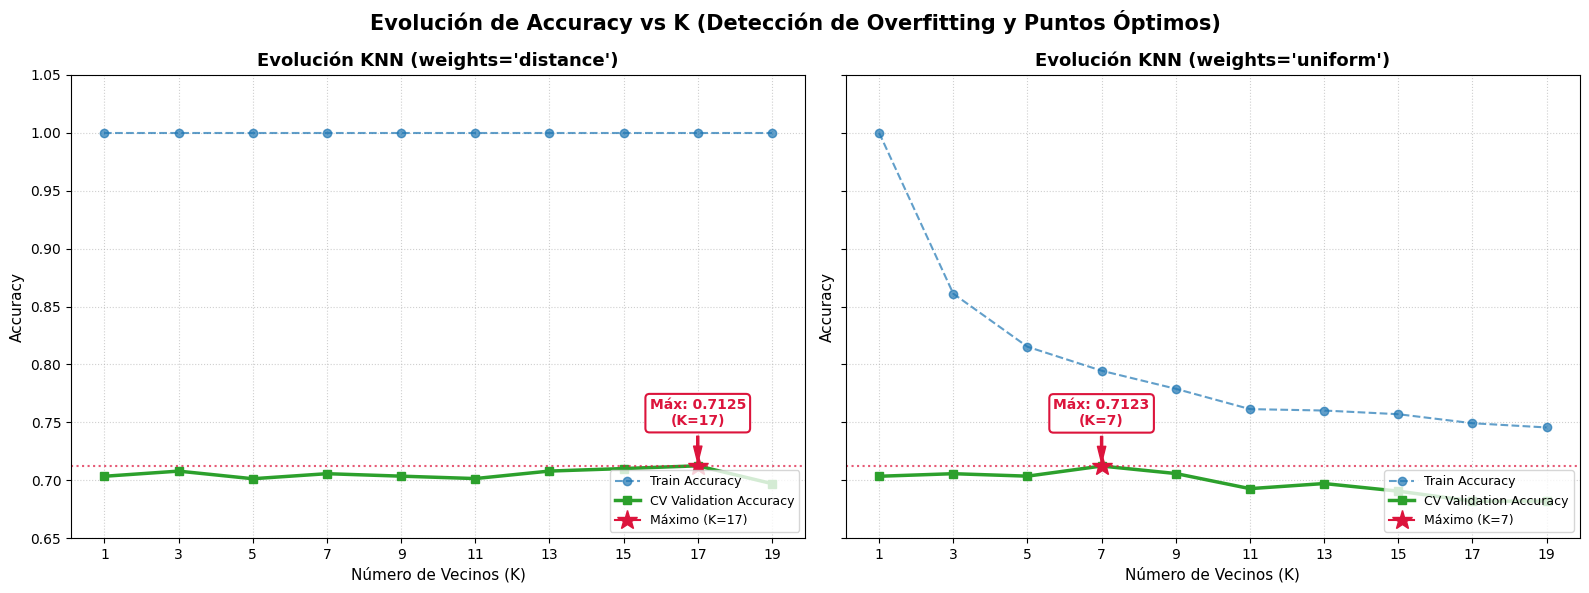

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for i, weight in enumerate(pesos):
    data_sub = df_results_knn[df_results_knn['weights'] == weight].copy()

    # 1. Curvas de Train y CV Validation
    axes[i].plot(data_sub['k'], data_sub['train_accuracy'], label='Train Accuracy', color='#1f77b4', linestyle='--', marker='o', alpha=0.7)
    axes[i].plot(data_sub['k'], data_sub['val_accuracy'], label='CV Validation Accuracy', color='#2ca02c', marker='s', linewidth=2.5)

    # 2. Localizar el punto máximo de validación
    max_row = data_sub.loc[data_sub['val_accuracy'].idxmax()]
    best_k = int(max_row['k'])
    max_val_acc = max_row['val_accuracy']

    # 3. Marcar el punto máximo con una estrella destacada
    axes[i].plot(best_k, max_val_acc, marker='*', markersize=15, color='crimson', zorder=5, label=f'Máximo (K={best_k})')

    # 4. Línea horizontal guía
    axes[i].axhline(y=max_val_acc, color='crimson', linestyle=':', alpha=0.7)

    # 5. Anotación con flecha y recuadro blanco
    axes[i].annotate(
        f"Máx: {max_val_acc:.4f}\n(K={best_k})",
        xy=(best_k, max_val_acc),
        xytext=(best_k, max_val_acc + 0.035),
        arrowprops=dict(facecolor='crimson', edgecolor='crimson', shrink=0.08, width=1.5, headwidth=6),
        ha='center', fontsize=10, fontweight='bold', color='crimson',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="crimson", lw=1.5)
    )

    axes[i].set_title(f"Evolución KNN (weights='{weight}')", fontsize=13, fontweight='bold')
    axes[i].set_xlabel("Número de Vecinos (K)", fontsize=11)
    axes[i].set_ylabel("Accuracy", fontsize=11)
    axes[i].set_xticks(num_vecinos)
    axes[i].set_ylim(0.65, 1.05)  # Margen superior ampliado para las etiquetas
    axes[i].grid(True, linestyle=':', alpha=0.6)
    axes[i].legend(loc='lower right', fontsize=9)

plt.suptitle("Evolución de Accuracy vs K (Detección de Overfitting y Puntos Óptimos)", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [88]:

best_k = int(mejor_config['k'])
best_weight = mejor_config['weights']

pipeline_knn.set_params(knn__n_neighbors=best_k, knn__weights=best_weight)
pipeline_knn.fit(X_train, y_train)

y_pred_knn_train = pipeline_knn.predict(X_train)
y_pred_knn_test = pipeline_knn.predict(X_test)

print("--- EVALUACIÓN KNN (TRAIN vs TEST) ---")
print(f"Train Accuracy:          {accuracy_score(y_train, y_pred_knn_train):.4f} | Test Accuracy:          {accuracy_score(y_test, y_pred_knn_test):.4f}")
print(f"Train Balanced Accuracy: {balanced_accuracy_score(y_train, y_pred_knn_train):.4f} | Test Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_knn_test):.4f}")
print(f"Train F1-Score:          {f1_score(y_train, y_pred_knn_train):.4f} | Test F1-Score:          {f1_score(y_test, y_pred_knn_test):.4f}\n")

--- EVALUACIÓN KNN (TRAIN vs TEST) ---
Train Accuracy:          1.0000 | Test Accuracy:          0.7456
Train Balanced Accuracy: 1.0000 | Test Balanced Accuracy: 0.5965
Train F1-Score:          1.0000 | Test F1-Score:          0.8415



In [89]:
# 1. Extraer la mejor combinación de K (impar) y weights óptima
best_k = int(mejor_config['k'])
best_weight = mejor_config['weights']

# 2. Construir el Pipeline final para KNN
final_pipeline_knn = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
    ('knn', KNeighborsClassifier(
        n_neighbors=best_k,
        weights=best_weight
    ))
])

# 3. Entrenar el modelo con el 100% del dataset
final_pipeline_knn.fit(X, y)

print("--- MODELO FINAL: KNN ---")
print("¡Entrenamiento completado sobre la totalidad de los datos!")
print(f"Configuración aplicada: n_neighbors = {best_k}, weights = '{best_weight}'")

--- MODELO FINAL: KNN ---
¡Entrenamiento completado sobre la totalidad de los datos!
Configuración aplicada: n_neighbors = 17, weights = 'distance'


In [90]:

# 1. Extraer los pasos del Pipeline
imputer = pipeline_knn.named_steps['imputer']
scaler = pipeline_knn.named_steps['scaler']
knn_model = pipeline_knn.named_steps['knn']

# 2. Transformar la muestra a explicar (ej. la primera fila de X_test)
muestra = X_test.iloc[[0]]
muestra_transformada = scaler.transform(imputer.transform(muestra))

# 3. Obtener las distancias e índices de los K vecinos en X_train
distancias, indices = knn_model.kneighbors(muestra_transformada)

# 4. Construir la tabla explicativa con los datos reales de los vecinos
vecinos_explicacion = X_train.iloc[indices[0]].copy()
vecinos_explicacion['Distancia_KNN'] = distancias[0]
vecinos_explicacion['Clase_Real'] = y_train.iloc[indices[0]].values

print("Instancia analizada:")
display(muestra)

print("\nLos K vecinos que determinaron su predicción:")
display(vecinos_explicacion)

Instancia analizada:


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio
358,33,1,0.8,0.2,135,30,29,7.2,4.4,1.5



Los K vecinos que determinaron su predicción:


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Distancia_KNN,Clase_Real
117,28,1,0.6,0.1,177,36,29,6.9,4.1,1.40,0.637131,0
208,47,1,0.9,0.2,192,38,24,7.3,4.3,1.40,0.832874,1
329,35,1,0.8,0.2,198,36,32,7.0,4.0,1.30,0.847318,0
460,42,1,1.0,0.3,154,38,21,6.8,3.9,1.30,0.878270,0
372,50,1,0.8,0.2,152,29,30,7.4,4.1,1.30,0.906163,1
391,22,1,0.8,0.2,198,20,26,6.8,3.9,1.30,1.044461,1
268,50,1,0.7,0.2,192,18,15,7.4,4.2,1.30,1.086197,0
97,17,1,0.9,0.2,224,36,45,6.9,4.2,1.55,1.094259,1
79,32,1,0.6,0.1,237,45,31,7.5,4.3,1.34,1.098605,1
483,24,1,1.0,0.2,189,52,31,8.0,4.8,1.50,1.117807,1


In [91]:
from sklearn.inspection import permutation_importance

# Evaluar el impacto de permutación en el conjunto de prueba/validación
resultado = permutation_importance(
    pipeline_knn,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='accuracy'
)

# Organizar en un DataFrame de importancia
importancia_vars = pd.DataFrame({
    'Variable': X_test.columns,
    'Importancia_Media': resultado.importances_mean,
    'Desviacion_Std': resultado.importances_std
}).sort_values(by='Importancia_Media', ascending=False)

display(importancia_vars)

,Variable,Importancia_Media,Desviacion_Std
4,Alkaline_Phosphotase,0.024561,0.022467
0,Age,0.021053,0.020832
7,Total_Protiens,0.015789,0.023472
6,Aspartate_Aminotransferase,0.014035,0.011234
2,Total_Bilirubin,0.011404,0.011801
5,Alamine_Aminotransferase,0.010526,0.019138
8,Albumin,0.010526,0.015092
1,Gender,0.009649,0.014912
9,Albumin_and_Globulin_Ratio,0.004386,0.019712
3,Direct_Bilirubin,0.001754,0.014573



--- EXPLICABILIDAD CON SHAP ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


  0%|          | 0/10 [00:00<?, ?it/s]

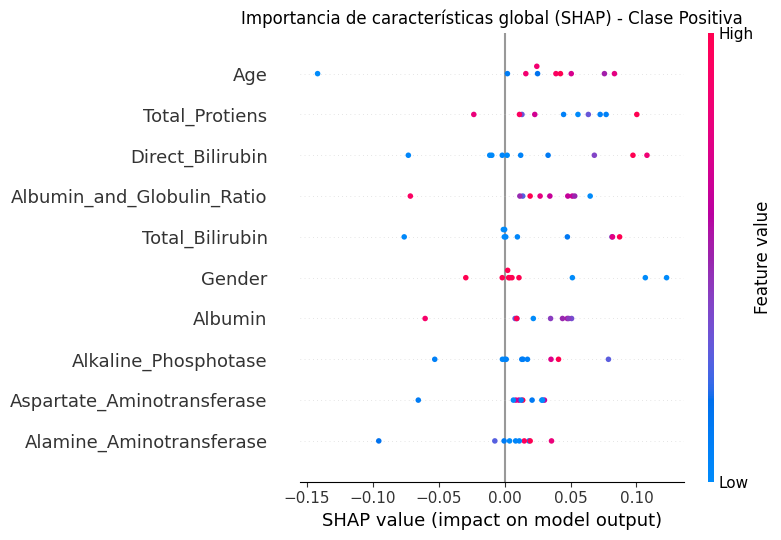

In [92]:
import shap
print("\n--- EXPLICABILIDAD CON SHAP ---")

# 1. Muestra representativa para acelerar KernelExplainer
background_data = shap.sample(X, 100)

model_predict = lambda x: final_pipeline_knn.predict_proba(x)

#Inicializar KernelExplainer usando la función wrapper
explainer_shap = shap.KernelExplainer(model_predict, background_data)

#Seleccionar las instancias a explicar (ej. las 10 primeras)
X_to_explain = X.iloc[:10] if hasattr(X, 'iloc') else X[:10]

#Calcular los valores SHAP ignorando warnings de SHAP
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    shap_values = explainer_shap.shap_values(X_to_explain)

if isinstance(shap_values, list):
    valores_clase_positiva = shap_values[1]
elif len(shap_values.shape) == 3:
    valores_clase_positiva = shap_values[:, :, 1]
else:
    valores_clase_positiva = shap_values

#Gráfico de resumen (Summary Plot) para la Clase 1
plt.figure(figsize=(10, 6))
plt.title("Importancia de características global (SHAP) - Clase Positiva")

shap.summary_plot(valores_clase_positiva, X_to_explain, show=False)
plt.tight_layout()
plt.show()
